<a href="https://colab.research.google.com/github/adibansal06/UCS420_CC_LabAssignments_1024170054/blob/main/UCS420_Assignment10_Heart_Health_Assistant_Aditya_Bansal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 – Cognitive Computing | Assignment 10
## Heart Health Information Assistant

**Student:** Aditya Bansal  
**Roll Number:** 1024170054  
**Section:** 3Q23  
**Institution:** Thapar Institute of Engineering & Technology, Patiala  
**Course:** UCS420 – Cognitive Computing  
**Classifier:** Logistic Regression

---

### Problem statement
Design and develop a Python-based healthcare cognitive assistant that understands user queries, identifies intent, retrieves relevant healthcare information, and generates appropriate responses.

### Objectives
1. Build a labelled corpus with at least 40 queries across 5 or more intent categories.
2. Create a hierarchical taxonomy with at least 4 major categories and 2 subcategories under each.
3. Identify at least 8 domain concepts and define at least 10 relationships.
4. Apply lowercase conversion, tokenization, stopword removal, and lemmatization.
5. Use TF-IDF and train a Logistic Regression classifier.
6. Evaluate using accuracy, precision, recall, F1-score, and a confusion matrix.
7. Create a heart-health knowledge base.
8. Implement rules for emergency escalation, low confidence, and unsupported queries.
9. Integrate NLP, classification, reasoning, and retrieval.
10. Provide an interactive interface that accepts multiple queries.

> **Safety note:** This is an educational information assistant, not a diagnostic tool. It cannot diagnose, prescribe, or replace a clinician. Emergency symptoms are escalated before machine-learning classification. In India, call **112** for emergency assistance or seek the nearest emergency department when urgent symptoms occur.

## 1. Environment setup

The notebook is designed for Google Colab. The next cell installs the required libraries. Run cells from top to bottom.

In [1]:
# Install the libraries used in this assignment.
!pip -q install nltk scikit-learn pandas matplotlib seaborn gradio

## 2. Import libraries and configure the environment

We use:
- **NLTK** for tokenization, stopword removal, and lemmatization.
- **scikit-learn** for TF-IDF, Logistic Regression, and evaluation.
- **pandas** for the labelled corpus and knowledge base.
- **matplotlib / seaborn** for the confusion matrix.
- **Gradio** for a simple interactive interface.

In [2]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Download language resources required by NLTK.
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

print("Libraries imported and NLTK resources are ready.")

Libraries imported and NLTK resources are ready.


## 3. Build the labelled query corpus

The corpus below contains **60 labelled example queries** across six intents. This exceeds the assignment minimum of 40 queries and five intent categories.

The labels represent the main information need:
- `heart_symptoms`
- `blood_pressure`
- `cholesterol`
- `healthy_lifestyle`
- `prevention_screening`
- `heart_medicines`

Emergency escalation is handled by a separate safety rule and is not dependent on the classifier.

In [3]:
data = [
    # Heart symptoms (10)
    ("What are common signs of heart disease?", "heart_symptoms"),
    ("Why do I feel breathless while walking?", "heart_symptoms"),
    ("Can heart problems cause unusual fatigue?", "heart_symptoms"),
    ("What does an irregular heartbeat feel like?", "heart_symptoms"),
    ("Is dizziness sometimes related to the heart?", "heart_symptoms"),
    ("What are palpitations?", "heart_symptoms"),
    ("Can swollen ankles be linked to heart problems?", "heart_symptoms"),
    ("Why might I feel short of breath at night?", "heart_symptoms"),
    ("What symptoms should I discuss with a cardiologist?", "heart_symptoms"),
    ("Can heart conditions cause weakness?", "heart_symptoms"),

    # Blood pressure (10)
    ("What is a normal blood pressure reading for adults?", "blood_pressure"),
    ("What does high blood pressure mean?", "blood_pressure"),
    ("How can I monitor my blood pressure at home?", "blood_pressure"),
    ("What lifestyle changes may lower blood pressure?", "blood_pressure"),
    ("Does too much salt affect blood pressure?", "blood_pressure"),
    ("What is systolic blood pressure?", "blood_pressure"),
    ("What is diastolic blood pressure?", "blood_pressure"),
    ("Why is regular blood pressure monitoring important?", "blood_pressure"),
    ("Can stress temporarily raise blood pressure?", "blood_pressure"),
    ("What should I ask my doctor about hypertension?", "blood_pressure"),

    # Cholesterol (10)
    ("What is LDL cholesterol?", "cholesterol"),
    ("What is HDL cholesterol?", "cholesterol"),
    ("Why is high cholesterol a concern for the heart?", "cholesterol"),
    ("Which foods can help improve cholesterol levels?", "cholesterol"),
    ("What is a lipid profile test?", "cholesterol"),
    ("How often should cholesterol be checked?", "cholesterol"),
    ("What are triglycerides?", "cholesterol"),
    ("Does exercise help manage cholesterol?", "cholesterol"),
    ("What is the difference between good and bad cholesterol?", "cholesterol"),
    ("What questions should I ask about my cholesterol report?", "cholesterol"),

    # Healthy lifestyle (10)
    ("What type of exercise supports heart health?", "healthy_lifestyle"),
    ("How much physical activity should adults aim for?", "healthy_lifestyle"),
    ("Which foods are part of a heart healthy diet?", "healthy_lifestyle"),
    ("Why is sleep important for cardiovascular health?", "healthy_lifestyle"),
    ("How does smoking affect the heart?", "healthy_lifestyle"),
    ("Can managing stress support heart health?", "healthy_lifestyle"),
    ("What are some heart healthy meal choices?", "healthy_lifestyle"),
    ("How can I start walking regularly?", "healthy_lifestyle"),
    ("Why should I limit excess salt and saturated fat?", "healthy_lifestyle"),
    ("How does alcohol affect cardiovascular health?", "healthy_lifestyle"),

    # Prevention and screening (10)
    ("How can I reduce my risk of heart disease?", "prevention_screening"),
    ("What is a cardiac risk factor?", "prevention_screening"),
    ("When should someone get a heart health checkup?", "prevention_screening"),
    ("What is an ECG used for?", "prevention_screening"),
    ("What is an echocardiogram?", "prevention_screening"),
    ("Why is family history relevant to heart disease?", "prevention_screening"),
    ("Can diabetes increase cardiovascular risk?", "prevention_screening"),
    ("Why are preventive health checkups useful?", "prevention_screening"),
    ("What should be included in a heart health review?", "prevention_screening"),
    ("How does maintaining a healthy weight help the heart?", "prevention_screening"),

    # Heart medicines (10)
    ("Why might a doctor prescribe medicine for blood pressure?", "heart_medicines"),
    ("What should I ask before starting a heart medicine?", "heart_medicines"),
    ("Why is it important to take prescribed medicine as directed?", "heart_medicines"),
    ("Can I stop my blood pressure medicine when I feel better?", "heart_medicines"),
    ("What information should I share about my current medicines?", "heart_medicines"),
    ("Can heart medicines have side effects?", "heart_medicines"),
    ("Why should I tell my doctor about other medicines I take?", "heart_medicines"),
    ("What should I do if I miss a prescribed dose?", "heart_medicines"),
    ("Should I discuss supplements with my cardiologist?", "heart_medicines"),
    ("How can I keep track of my prescribed medicines?", "heart_medicines"),
]

corpus = pd.DataFrame(data, columns=["query", "intent"])
print("Number of labelled queries:", len(corpus))
print("\nQueries per intent:")
display(corpus["intent"].value_counts().rename_axis("intent").to_frame("count"))
display(corpus.head())

Number of labelled queries: 60

Queries per intent:


,count
intent,
heart_symptoms,10
blood_pressure,10
cholesterol,10
healthy_lifestyle,10
prevention_screening,10
heart_medicines,10


,query,intent
0,What are common signs of heart disease?,heart_symptoms
1,Why do I feel breathless while walking?,heart_symptoms
2,Can heart problems cause unusual fatigue?,heart_symptoms
3,What does an irregular heartbeat feel like?,heart_symptoms
4,Is dizziness sometimes related to the heart?,heart_symptoms


## 4. Hierarchical heart-health taxonomy

A taxonomy organizes the domain from broad categories to more specific subcategories. The assignment asks for at least four major categories and two subcategories under each; the hierarchy below provides five major categories.

In [4]:
taxonomy = {
    "Cardiovascular symptoms": [
        "Common symptoms and warning signs",
        "Breathing, fatigue and palpitations"
    ],
    "Risk factors and measurements": [
        "Blood pressure",
        "Cholesterol and lipid profile"
    ],
    "Healthy living": [
        "Diet and nutrition",
        "Physical activity, sleep and stress"
    ],
    "Prevention and assessment": [
        "Screening and clinical tests",
        "Family history and risk reduction"
    ],
    "Treatment support": [
        "Prescribed heart medicines",
        "Medication safety and follow-up"
    ]
}

for major, subcategories in taxonomy.items():
    print(f"• {major}")
    for sub in subcategories:
        print(f"    └── {sub}")

• Cardiovascular symptoms
    └── Common symptoms and warning signs
    └── Breathing, fatigue and palpitations
• Risk factors and measurements
    └── Blood pressure
    └── Cholesterol and lipid profile
• Healthy living
    └── Diet and nutrition
    └── Physical activity, sleep and stress
• Prevention and assessment
    └── Screening and clinical tests
    └── Family history and risk reduction
• Treatment support
    └── Prescribed heart medicines
    └── Medication safety and follow-up


## 5. Domain ontology: concepts and relationships

An ontology represents important domain concepts and how they relate. This small educational ontology contains more than eight concepts and ten relationships. It is a simplified conceptual model, not a clinical knowledge graph.

In [5]:
concepts = [
    "Heart", "Blood pressure", "Cholesterol", "Blood vessels",
    "Physical activity", "Diet", "Smoking", "Diabetes",
    "Medication", "Clinical screening", "Cardiovascular risk",
    "Healthcare professional"
]

relationships = [
    ("Blood pressure", "is_measurement_related_to", "Cardiovascular risk"),
    ("Cholesterol", "can_contribute_to", "Cardiovascular risk"),
    ("Blood vessels", "carry_blood_from_and_to", "Heart"),
    ("Smoking", "can_increase", "Cardiovascular risk"),
    ("Diabetes", "can_increase", "Cardiovascular risk"),
    ("Physical activity", "can_help_manage", "Cardiovascular risk"),
    ("Diet", "can_influence", "Cholesterol"),
    ("Diet", "can_influence", "Blood pressure"),
    ("Clinical screening", "can_assess", "Cardiovascular risk"),
    ("Healthcare professional", "evaluates", "Clinical screening"),
    ("Healthcare professional", "prescribes_when_appropriate", "Medication"),
    ("Medication", "may_be_used_to_manage", "Blood pressure"),
]

print(f"Number of concepts: {len(concepts)}")
print(f"Number of relationships: {len(relationships)}")
print("\nConcepts:")
for concept in concepts:
    print("-", concept)

ontology_df = pd.DataFrame(relationships, columns=["source", "relationship", "target"])
display(ontology_df)

Number of concepts: 12
Number of relationships: 12

Concepts:
- Heart
- Blood pressure
- Cholesterol
- Blood vessels
- Physical activity
- Diet
- Smoking
- Diabetes
- Medication
- Clinical screening
- Cardiovascular risk
- Healthcare professional


,source,relationship,target
0,Blood pressure,is_measurement_related_to,Cardiovascular risk
1,Cholesterol,can_contribute_to,Cardiovascular risk
2,Blood vessels,carry_blood_from_and_to,Heart
3,Smoking,can_increase,Cardiovascular risk
4,Diabetes,can_increase,Cardiovascular risk
5,Physical activity,can_help_manage,Cardiovascular risk
6,Diet,can_influence,Cholesterol
7,Diet,can_influence,Blood pressure
8,Clinical screening,can_assess,Cardiovascular risk
9,Healthcare professional,evaluates,Clinical screening


## 6. Text preprocessing

The preprocessing function performs the four required operations:
1. Lowercase conversion.
2. Tokenization.
3. Stopword removal.
4. Lemmatization.

We retain meaningful tokens and remove punctuation. The same preprocessing function is used by the TF-IDF vectorizer so training and inference follow the same steps.

In [6]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # 1. Lowercase conversion
    text = str(text).lower()

    # 2. Tokenization
    tokens = word_tokenize(text)

    # Keep alphabetic tokens; 3. remove stopwords; 4. lemmatize.
    cleaned_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token.isalpha() and token not in stop_words
    ]
    return " ".join(cleaned_tokens)

sample = "How can regular exercise help improve heart health?"
print("Original :", sample)
print("Processed:", preprocess_text(sample))

Original : How can regular exercise help improve heart health?
Processed: regular exercise help improve heart health


## 7. Train-test split and TF-IDF + Logistic Regression

TF-IDF converts text into numerical features. Logistic Regression learns to map these features to the six intent labels.

A stratified split preserves the class proportions in both training and test sets. With this deliberately small teaching corpus, the evaluation score is illustrative and should not be interpreted as real-world clinical performance.

In [7]:
X = corpus["query"]
y = corpus["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        preprocessor=preprocess_text,
        tokenizer=str.split,
        token_pattern=None,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

model.fit(X_train, y_train)
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))
print("Model training completed.")

Training samples: 42
Testing samples : 18
Model training completed.


## 8. Model evaluation

We report accuracy, macro-averaged precision, recall and F1-score. Macro averaging gives each intent equal weight. The confusion matrix shows which labels the model predicts correctly or confuses.

**Interpretation:** These metrics evaluate intent recognition on a small held-out sample. They do not measure medical correctness, safety, or suitability for patient care.

,Metric,Score
0,Accuracy,0.667
1,Macro Precision,0.692
2,Macro Recall,0.667
3,Macro F1-score,0.660



Classification report:
                      precision    recall  f1-score   support

      blood_pressure       0.75      1.00      0.86         3
         cholesterol       1.00      0.67      0.80         3
   healthy_lifestyle       0.50      0.33      0.40         3
     heart_medicines       1.00      1.00      1.00         3
      heart_symptoms       0.40      0.67      0.50         3
prevention_screening       0.50      0.33      0.40         3

            accuracy                           0.67        18
           macro avg       0.69      0.67      0.66        18
        weighted avg       0.69      0.67      0.66        18



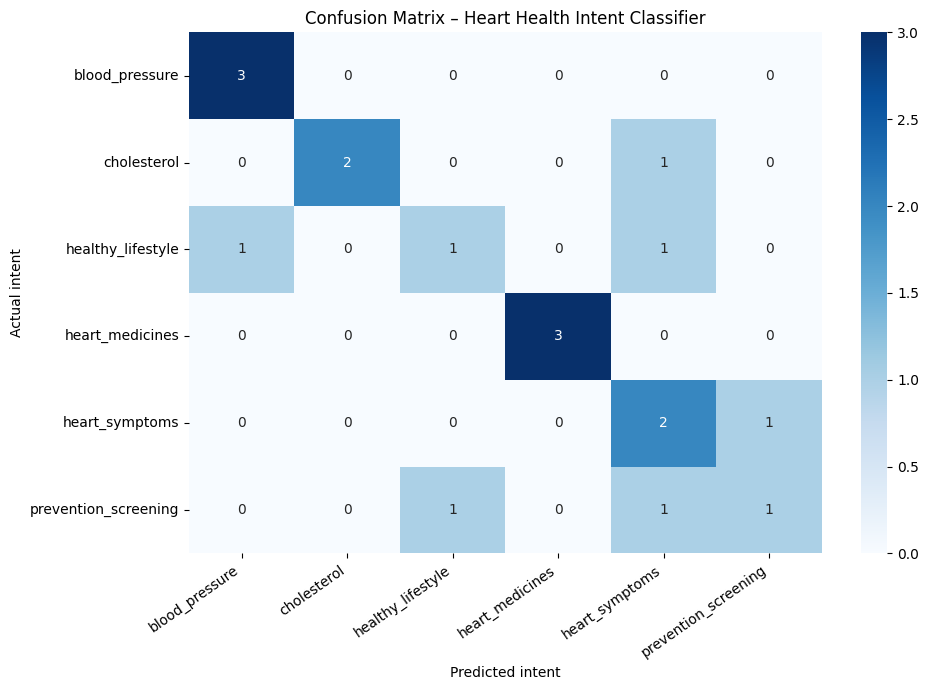

Interpretation:
- Accuracy is the proportion of test queries assigned the correct intent.
- Macro precision measures the average precision across intents.
- Macro recall measures the average recall across intents.
- Macro F1 balances precision and recall across intents.
- Off-diagonal confusion-matrix values indicate misclassified test queries.


In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"],
    "Score": [accuracy, precision, recall, f1]
})
display(metrics_df.style.format({"Score": "{:.3f}"}))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(corpus["intent"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted intent")
plt.ylabel("Actual intent")
plt.title("Confusion Matrix – Heart Health Intent Classifier")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Interpretation:")
print("- Accuracy is the proportion of test queries assigned the correct intent.")
print("- Macro precision measures the average precision across intents.")
print("- Macro recall measures the average recall across intents.")
print("- Macro F1 balances precision and recall across intents.")
print("- Off-diagonal confusion-matrix values indicate misclassified test queries.")

## 9. Heart-health knowledge base

The knowledge base maps each supported intent to general educational information and a suggested next step. It deliberately avoids diagnosis, individualized treatment, medication dosing, and medication changes.

Health recommendations vary by age, medical history, pregnancy status, and other factors. Users should discuss personal decisions with a qualified healthcare professional.

In [9]:
knowledge_base = {
    "heart_symptoms": {
        "title": "Heart-related symptoms",
        "information": (
            "Possible symptoms associated with cardiovascular conditions include "
            "breathlessness, unusual fatigue, palpitations, dizziness, and swelling. "
            "These symptoms can have many causes and cannot establish a diagnosis on their own."
        ),
        "next_step": "Note when symptoms occur, how long they last, and what makes them better or worse. Discuss persistent or concerning symptoms with a healthcare professional."
    },
    "blood_pressure": {
        "title": "Blood pressure",
        "information": (
            "Blood pressure is recorded using systolic and diastolic values. "
            "Repeated measurements, taken with a correctly sized cuff and proper technique, "
            "are more informative than a single reading."
        ),
        "next_step": "Keep a record of readings and discuss them with a clinician. Do not start, stop, or change medication based on this assistant."
    },
    "cholesterol": {
        "title": "Cholesterol and lipid profile",
        "information": (
            "A lipid profile commonly reports LDL cholesterol, HDL cholesterol, and triglycerides. "
            "Interpretation depends on the overall cardiovascular risk profile, not one number alone."
        ),
        "next_step": "Review your complete lipid report with a healthcare professional, who can interpret it in the context of your health history."
    },
    "healthy_lifestyle": {
        "title": "Heart-healthy lifestyle",
        "information": (
            "Heart-supportive habits include regular physical activity suited to your abilities, "
            "a balanced diet, adequate sleep, avoiding tobacco, and managing stress. "
            "Choose sustainable changes rather than extreme routines."
        ),
        "next_step": "If you have symptoms or a health condition, ask a clinician what level of activity and dietary changes are appropriate for you."
    },
    "prevention_screening": {
        "title": "Prevention and screening",
        "information": (
            "Cardiovascular risk assessment may consider blood pressure, cholesterol, diabetes, "
            "smoking, family history, age, and other factors. Tests such as ECG or echocardiography "
            "are used when clinically indicated."
        ),
        "next_step": "Ask a healthcare professional which screening or assessment is appropriate for your age, history, and symptoms."
    },
    "heart_medicines": {
        "title": "Heart medicines – general information",
        "information": (
            "Medicines may be prescribed for conditions such as high blood pressure or cholesterol. "
            "The correct medicine and dose are individualized. Medicines can have side effects "
            "and interactions."
        ),
        "next_step": "Follow the prescriber's instructions. Ask your doctor or pharmacist before changing a dose, stopping treatment, or combining medicines or supplements."
    }
}

for intent, entry in knowledge_base.items():
    print(f"\n{intent}: {entry['title']}")
    print(entry["information"])


heart_symptoms: Heart-related symptoms
Possible symptoms associated with cardiovascular conditions include breathlessness, unusual fatigue, palpitations, dizziness, and swelling. These symptoms can have many causes and cannot establish a diagnosis on their own.

blood_pressure: Blood pressure
Blood pressure is recorded using systolic and diastolic values. Repeated measurements, taken with a correctly sized cuff and proper technique, are more informative than a single reading.

cholesterol: Cholesterol and lipid profile
A lipid profile commonly reports LDL cholesterol, HDL cholesterol, and triglycerides. Interpretation depends on the overall cardiovascular risk profile, not one number alone.

healthy_lifestyle: Heart-healthy lifestyle
Heart-supportive habits include regular physical activity suited to your abilities, a balanced diet, adequate sleep, avoiding tobacco, and managing stress. Choose sustainable changes rather than extreme routines.

prevention_screening: Prevention and scre

## 10. Rule-based reasoning and safety layer

The assistant applies rules before returning a normal knowledge-base response:

1. **Emergency escalation:** potentially urgent symptoms are escalated immediately, before model prediction.
2. **Low-confidence handling:** uncertain predictions are not presented as reliable intent matches.
3. **Unsupported-query handling:** queries with insufficient overlap with the training vocabulary are redirected.
4. **Medication safety:** medication changes and dosing requests are referred to a clinician or pharmacist.
5. **General-information rule:** supported intents retrieve the matching knowledge-base entry.

The keyword emergency detector is intentionally conservative but cannot detect every emergency. It is not a substitute for emergency services.

In [10]:
EMERGENCY_PATTERNS = [
    r"chest pain", r"chest pressure", r"chest tightness",
    r"can't breathe", r"cannot breathe", r"severe shortness of breath",
    r"fainting", r"passed out", r"stroke", r"face drooping",
    r"one side.*weak", r"sudden weakness", r"blue lips"
]

MEDICATION_CHANGE_PATTERNS = [
    r"stop.*(medicine|medication|tablet|drug)",
    r"change.*(dose|dosage)",
    r"increase.*(dose|dosage)",
    r"decrease.*(dose|dosage)",
    r"how many.*(tablet|pill)",
    r"what dose"
]

def is_emergency_query(query):
    q = str(query).lower()
    return any(re.search(pattern, q) for pattern in EMERGENCY_PATTERNS)

def is_medication_change_query(query):
    q = str(query).lower()
    return any(re.search(pattern, q) for pattern in MEDICATION_CHANGE_PATTERNS)

# A minimum confidence threshold triggers safe fallback rather than a forced answer.
CONFIDENCE_THRESHOLD = 0.35

# TF-IDF vocabulary is used as a simple out-of-domain signal.
def has_vocabulary_overlap(query):
    vectorizer = model.named_steps["tfidf"]
    query_vector = vectorizer.transform([query])
    return query_vector.nnz > 0

print("Safety and reasoning rules are configured.")

Safety and reasoning rules are configured.


## 11. Integrate NLP, classification, reasoning, and retrieval

The function below is the complete assistant pipeline:
1. Check emergency indicators.
2. Apply medication-safety handling.
3. Check whether the query overlaps with known vocabulary.
4. Predict intent and confidence.
5. Apply the low-confidence rule.
6. Retrieve the relevant knowledge-base response.

In [11]:
def heart_health_assistant(query):
    query = str(query).strip()

    if not query:
        return "Please enter a question about heart health."

    # Rule 1: Emergency escalation always takes priority over ML classification.
    if is_emergency_query(query):
        return (
            "URGENT SAFETY MESSAGE: Your message may describe a medical emergency. "
            "Call 112 in India or your local emergency number now, or go to the nearest "
            "emergency department. Do not drive yourself if you may be seriously unwell. "
            "This assistant cannot assess or rule out an emergency."
        )

    # Rule 2: Do not provide medication dose or treatment-change instructions.
    if is_medication_change_query(query):
        return (
            "Medication safety: I cannot recommend a dose change or tell you to stop "
            "a prescribed medicine. Contact your prescribing doctor or pharmacist for "
            "individual advice. If you are having a severe reaction or feel acutely unwell, "
            "seek urgent medical help."
        )

    # Rule 3: Unsupported-query handling.
    if not has_vocabulary_overlap(query):
        return (
            "I could not match this question to the heart-health topics covered by this "
            "educational assistant. Please ask about symptoms, blood pressure, cholesterol, "
            "healthy lifestyle, prevention/screening, or general heart-medicine information."
        )

    # Intent classification and confidence estimation.
    probabilities = model.predict_proba([query])[0]
    predicted_index = int(np.argmax(probabilities))
    intent = model.classes_[predicted_index]
    confidence = float(probabilities[predicted_index])

    # Rule 4: Low-confidence handling.
    if confidence < CONFIDENCE_THRESHOLD:
        return (
            "I am not sufficiently confident about the topic of your question "
            f"(model confidence: {confidence:.2f}). Please rephrase it or consult "
            "a healthcare professional for personal medical guidance."
        )

    # Rule 5: Retrieve a domain-specific response.
    entry = knowledge_base[intent]
    return (
        f"Detected topic: {entry['title']}\n"
        f"Model confidence: {confidence:.2f}\n\n"
        f"Information: {entry['information']}\n\n"
        f"Suggested next step: {entry['next_step']}\n\n"
        "Reminder: Educational information only; not a diagnosis or a substitute for professional care."
    )

print(heart_health_assistant("What is LDL cholesterol?"))

Detected topic: Cholesterol and lipid profile
Model confidence: 0.41

Information: A lipid profile commonly reports LDL cholesterol, HDL cholesterol, and triglycerides. Interpretation depends on the overall cardiovascular risk profile, not one number alone.

Suggested next step: Review your complete lipid report with a healthcare professional, who can interpret it in the context of your health history.

Reminder: Educational information only; not a diagnosis or a substitute for professional care.


## 12. Required test scenarios

The assignment specifically asks for:
1. A query belonging to each defined intent.
2. A differently worded query.
3. An unsupported healthcare query.
4. A low-confidence query.
5. An emergency-related query.

The examples below exercise each intent and the assistant's safety/fallback paths. Model confidence and classification results may vary if the corpus or train-test split is changed.

In [12]:
test_queries = [
    ("Intent: heart symptoms", "Why am I unusually breathless when I walk?"),
    ("Intent: blood pressure", "How do I check my BP at home?"),
    ("Intent: cholesterol", "Can you explain HDL and LDL?"),
    ("Intent: healthy lifestyle", "What exercise and food choices are good for my heart?"),
    ("Intent: prevention and screening", "Which tests help assess cardiovascular risk?"),
    ("Intent: heart medicines", "What should I ask my pharmacist about my heart tablets?"),
    ("Differently worded query", "My heartbeat sometimes feels like it skips."),
    ("Unsupported healthcare query", "How can I treat a skin rash?"),
    ("Low-confidence / ambiguous query", "Tell me about something."),
    ("Emergency-related query", "I have severe chest pain and cannot breathe.")
]

for label, query in test_queries:
    print("=" * 90)
    print(label)
    print("Query:", query)
    print(heart_health_assistant(query))
    print()

Intent: heart symptoms
Query: Why am I unusually breathless when I walk?
I am not sufficiently confident about the topic of your question (model confidence: 0.24). Please rephrase it or consult a healthcare professional for personal medical guidance.

Intent: blood pressure
Query: How do I check my BP at home?
I am not sufficiently confident about the topic of your question (model confidence: 0.19). Please rephrase it or consult a healthcare professional for personal medical guidance.

Intent: cholesterol
Query: Can you explain HDL and LDL?
I am not sufficiently confident about the topic of your question (model confidence: 0.28). Please rephrase it or consult a healthcare professional for personal medical guidance.

Intent: healthy lifestyle
Query: What exercise and food choices are good for my heart?
I am not sufficiently confident about the topic of your question (model confidence: 0.23). Please rephrase it or consult a healthcare professional for personal medical guidance.

Intent: 

## 13. Interactive multi-query interface

This Gradio interface accepts repeated questions in one session. It returns the assistant's response for each submitted query. The notebook also includes a simple batch function for testing multiple questions in one cell.

In [13]:
def answer_multiple_queries(queries):
    if isinstance(queries, str):
        queries = [q.strip() for q in queries.split("\n") if q.strip()]
    return "\n\n".join(
        [f"Q{i+1}: {q}\n{heart_health_assistant(q)}"
         for i, q in enumerate(queries)]
    )

# Quick batch demonstration
batch_questions = [
    "What is high blood pressure?",
    "How can I improve my cholesterol?",
    "I have chest pressure and severe shortness of breath."
]
print(answer_multiple_queries(batch_questions))

Q1: What is high blood pressure?
Detected topic: Blood pressure
Model confidence: 0.43

Information: Blood pressure is recorded using systolic and diastolic values. Repeated measurements, taken with a correctly sized cuff and proper technique, are more informative than a single reading.

Suggested next step: Keep a record of readings and discuss them with a clinician. Do not start, stop, or change medication based on this assistant.

Reminder: Educational information only; not a diagnosis or a substitute for professional care.

Q2: How can I improve my cholesterol?
I am not sufficiently confident about the topic of your question (model confidence: 0.35). Please rephrase it or consult a healthcare professional for personal medical guidance.

Q3: I have chest pressure and severe shortness of breath.
URGENT SAFETY MESSAGE: Your message may describe a medical emergency. Call 112 in India or your local emergency number now, or go to the nearest emergency department. Do not drive yourself if

In [14]:
# Launch the interactive interface in Google Colab.
# Set share=True to create a temporary public link if you need to open it
# outside the notebook. Do not enter personal medical information.
import gradio as gr

demo = gr.Interface(
    fn=heart_health_assistant,
    inputs=gr.Textbox(
        lines=3,
        placeholder="Ask a general heart-health question...",
        label="Your question"
    ),
    outputs=gr.Textbox(lines=10, label="Assistant response"),
    title="Heart Health Information Assistant",
    description=(
        "UCS420 Cognitive Computing – Assignment 10 | "
        "Educational information only; not for diagnosis or emergencies."
    ),
    examples=[
        "What is a normal blood pressure reading for adults?",
        "What is LDL cholesterol?",
        "What type of exercise supports heart health?",
        "What is an ECG used for?"
    ]
)

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d7a6dc5add0b2f27a5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 14. Conclusion and learning outcomes

The Heart Health Information Assistant demonstrates a complete introductory cognitive-computing pipeline:

- A labelled corpus represents common heart-health information needs.
- A hierarchical taxonomy and ontology organize the domain.
- NLP preprocessing normalizes user text.
- TF-IDF converts text into numerical features.
- Logistic Regression predicts the most likely intent.
- Evaluation metrics and a confusion matrix assess classification performance.
- A knowledge base retrieves intent-specific educational information.
- Rule-based reasoning handles emergency indicators, medication-change requests, low confidence, and unsupported questions.
- Gradio provides an interactive interface for user queries.

### Limitations and responsible use
- The corpus is small and manually authored; model performance on real-world language may be lower.
- Keyword-based emergency detection can miss symptoms or flag harmless mentions. It must never be used to rule out an emergency.
- The assistant does not diagnose conditions, interpret an individual's test results, recommend medication doses, or provide individualized treatment.
- Any real deployment would require clinical review, privacy/security controls, a much larger validated dataset, and formal safety evaluation.

### Final checklist against the assignment
| Requirement | Implementation |
|---|---|
| 40+ labelled queries, 5+ intents | 60 queries, 6 intents |
| 4+ major taxonomy categories, 2+ subcategories each | 5 major categories, 2 subcategories each |
| 8+ concepts and 10+ relationships | 12 concepts, 12 relationships |
| Required NLP preprocessing | Lowercase, tokenize, stopword removal, lemmatize |
| TF-IDF + classifier | TF-IDF + Logistic Regression |
| Evaluation metrics | Accuracy, precision, recall, F1, confusion matrix |
| Domain knowledge base | Six intent-specific entries |
| 5+ reasoning rules | Emergency, medication safety, unsupported, low confidence, retrieval |
| Integrated assistant | `heart_health_assistant()` |
| Interactive Colab interface | Gradio interface and batch queries |

**End of Assignment 10**